# 用 OpenCV 觀察卷積核的效果

深度學習課程實作（2025/10）。用 `cv2.filter2D` 套用四種 3×3 卷積核，觀察卷積如何抽取影像特徵，作為理解 CNN 卷積層的基礎。

2026/10 整理時修正了兩個問題：
1. **顏色錯誤**：`cv2.imread` 讀進來是 BGR 順序，`plt.imshow` 卻當成 RGB，顯示時藍色和橘色會互換。顯示前改成先轉回 RGB。
2. **Sobel 只看到一半的邊緣**：輸出深度用 `-1` 會沿用 uint8，負值全被截成 0，只剩「暗→亮」方向的邊緣。改成用 `cv2.CV_64F` 計算再取絕對值。

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## 讀取圖片

範例圖使用 scikit-image 內建的貓咪照片 `chelsea`。想換成自己的照片，改用 `src = cv2.imread("your_image.jpg")` 即可（讀進來同樣是 BGR）。

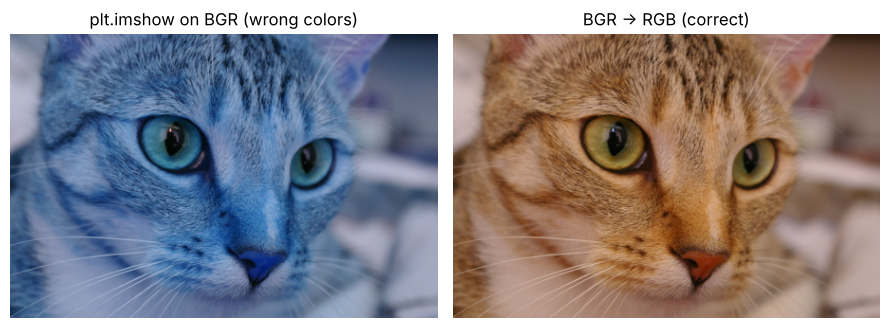

In [2]:
# skimage 給的是 RGB，轉成 OpenCV 慣用的 BGR，讓後面的流程和 cv2.imread 一致
src = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR)

def show(images, titles, size=(13, 4)):
    """把多張 BGR 影像並排顯示（顯示前轉回 RGB）"""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, img, t in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(t)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# 示範 BGR 問題：左邊直接顯示（顏色錯），右邊轉回 RGB 後顯示（正確）
# 圖內標題用英文，因為 Colab 預設沒有中文字型
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].imshow(src); axes[0].set_title("plt.imshow on BGR (wrong colors)")
axes[1].imshow(cv2.cvtColor(src, cv2.COLOR_BGR2RGB)); axes[1].set_title("BGR -> RGB (correct)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 1. Sobel 垂直邊緣（x 方向梯度）

卷積核 `[[-1,0,1],[-2,0,2],[-1,0,1]]` 計算左右兩側的亮度差，垂直的線條會被強化。
比較兩種寫法：輸出深度 `-1`（uint8，負值被截掉）只留下一半的邊緣；用 `CV_64F` 計算再取絕對值，兩個方向的邊緣都會出現。

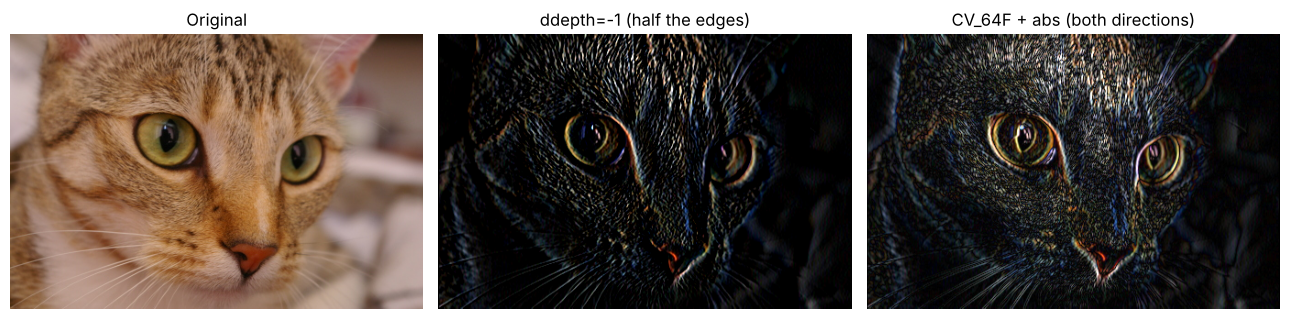

In [3]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype="float32")

half  = cv2.filter2D(src, -1, sobel_x)                                  # 原本寫法：只剩正值
full  = cv2.convertScaleAbs(cv2.filter2D(src, cv2.CV_64F, sobel_x))    # 修正：取絕對值
show([src, half, full], ["Original", "ddepth=-1 (half the edges)", "CV_64F + abs (both directions)"])

## 2. Sobel 水平邊緣（y 方向梯度）

把同一個卷積核轉置成 `[[-1,-2,-1],[0,0,0],[1,2,1]]`，改成比較上下的亮度差，強化水平線條。

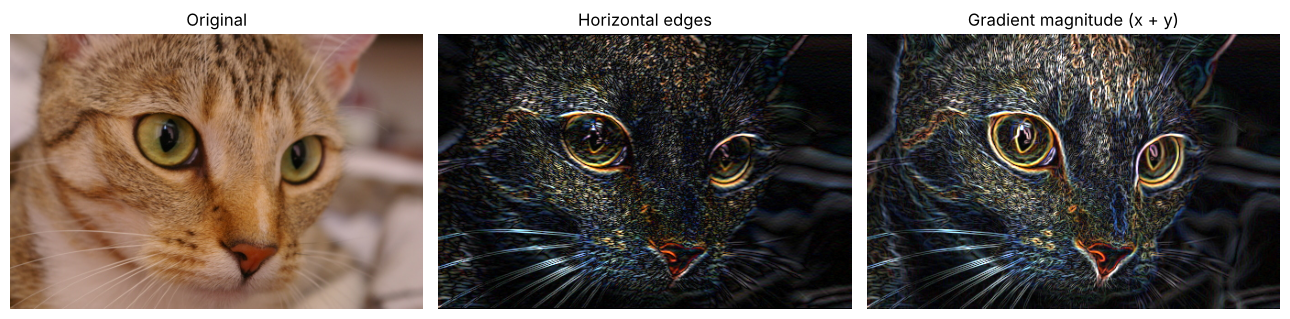

In [4]:
sobel_y = sobel_x.T
edges_y = cv2.convertScaleAbs(cv2.filter2D(src, cv2.CV_64F, sobel_y))

# 兩個方向合併成梯度強度
gx = cv2.filter2D(src, cv2.CV_64F, sobel_x)
gy = cv2.filter2D(src, cv2.CV_64F, sobel_y)
magnitude = cv2.convertScaleAbs(np.sqrt(gx**2 + gy**2))

show([src, edges_y, magnitude], ["Original", "Horizontal edges", "Gradient magnitude (x + y)"])

## 3. 銳化

卷積核 `[[0,-1,0],[-1,5,-1],[0,-1,0]]` 的總和是 1，整體亮度不變；中心加權、減去上下左右鄰居，讓邊緣和細節更明顯。這裡超出 0–255 的值本來就該截斷，所以直接用 `-1` 沒有問題。

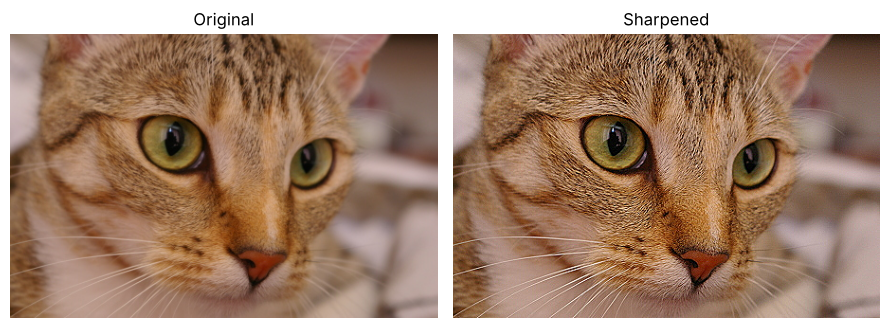

In [5]:
sharpen = np.array([[ 0, -1,  0],
                    [-1,  5, -1],
                    [ 0, -1,  0]], dtype="float32")
show([src, cv2.filter2D(src, -1, sharpen)], ["Original", "Sharpened"], size=(9, 3.5))

## 4. 只有右側一欄的卷積核

卷積核 `[[0,0,1],[0,0,1],[0,0,1]]`：每個輸出像素等於「右邊一欄、上下共 3 個像素」的總和。
- 總和是 3，所以畫面變亮約 3 倍，大部分區域直接飽和成白色
- 只取右側一欄，所以影像會往左平移 1 像素，並在垂直方向稍微模糊

把卷積核除以 3 讓總和變回 1，就只剩平移與垂直模糊的效果。這說明卷積核的**總和**決定整體亮度、**形狀**決定效果。

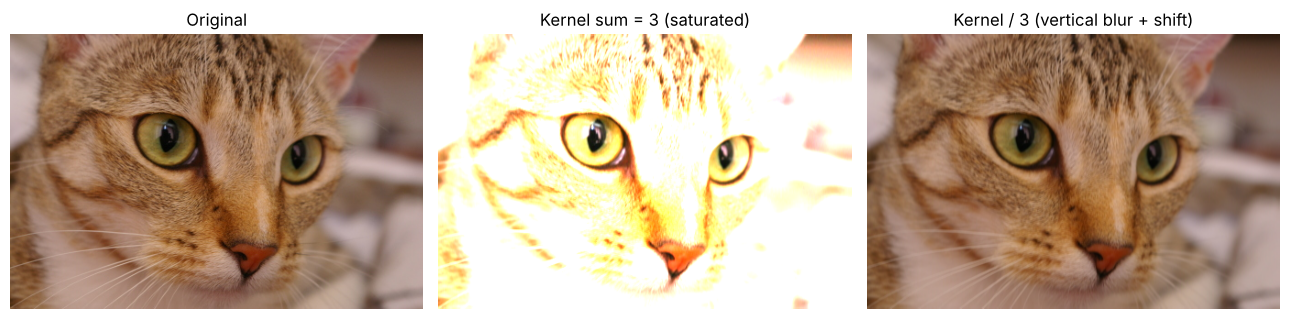

In [6]:
right_col = np.array([[0, 0, 1],
                      [0, 0, 1],
                      [0, 0, 1]], dtype="float32")
show([src, cv2.filter2D(src, -1, right_col), cv2.filter2D(src, -1, right_col / 3)],
     ["Original", "Kernel sum = 3 (saturated)", "Kernel / 3 (vertical blur + shift)"])